# Notebook for Generating simulated data

In [9]:
import sys
sys.path.insert(0, "..")

from simulation.observation_handler import ObservationHandler
from simulation.loads import Load
from simulation.receiver import Receiver

import matplotlib.pyplot as plt
import numpy as np
import astropy.units as un

from utils.utils import gamma_db_to_impedence
import os

plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams.update({
    "font.family": "serif"
})

# Time Static Case

Thermal Drifts

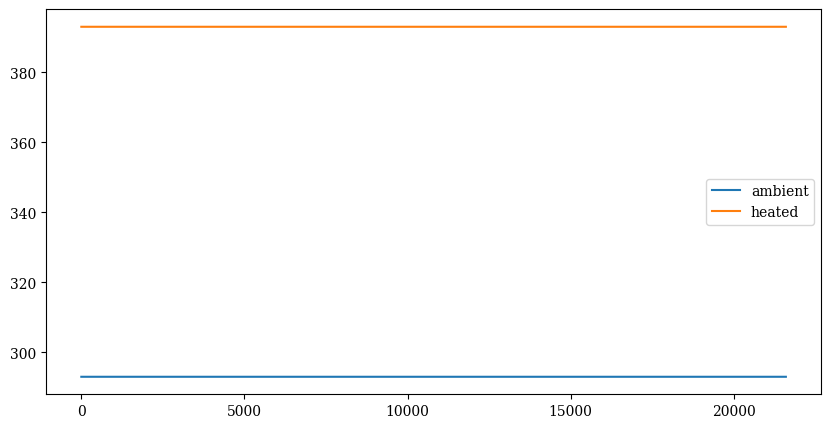

heated_temps:  [393. 393. 393. ... 393. 393. 393.]
ambient_temps:  [293. 293. 293. ... 293. 293. 293.]


In [15]:
# generate physical temperatures and drifts
#--------
# add here
ambient_rms = 3
heated_rms = 1
drift_order = 1

ambient_coeffs = ambient_rms * np.random.randn(drift_order)
ambient_coeffs[0] = 293
heated_coeffs = heated_rms * np.random.randn(drift_order)
heated_coeffs[0] = 293+100
n_times = 3600
xx = np.linspace(-1, 1, n_times)
times = np.linspace(0, 6*3600, n_times)
ambient_temps = np.polynomial.chebyshev.Chebyshev(ambient_coeffs)(xx)
heated_temps = np.polynomial.chebyshev.Chebyshev(heated_coeffs)(xx)
plt.plot(times, ambient_temps, label='ambient')
plt.plot(times, heated_temps, label='heated')
plt.legend()
plt.show()

print("heated_temps: ", heated_temps)
print("ambient_temps: ", ambient_temps)

Receiver Configuation

internal_load
heated_load
Done


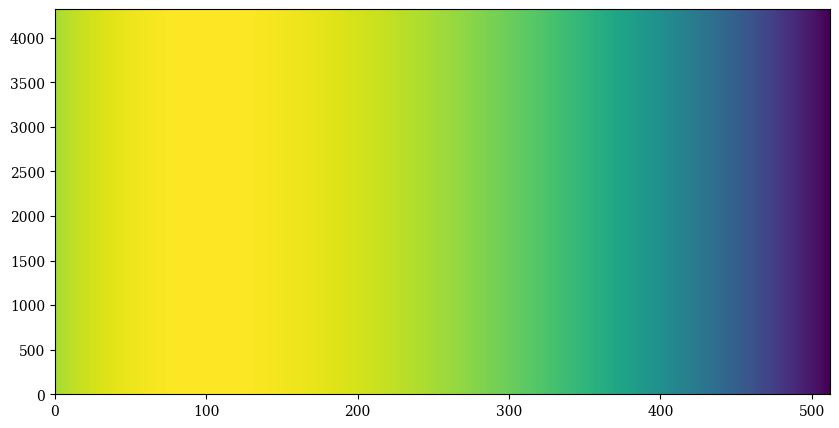

In [ ]:
test_receiver = Receiver(
    gamma_rec_s2p_path='../lab_measurements/RecBlockSDR0.s2p',
    gains_s2p_path='../lab_measurements/RecBlock0.s2p',
    t_unc_scale=300,
    t_sin_scale=25,
    t_cos_scale=-25,
    t_0_scale=400
    )

test_receiver.change_freqs(np.linspace(60*un.MHz, 80*un.MHz, 1024))

open_load = Load(
                 label='open',
                 termination_type='open',
                 freqs=test_receiver.freqs,
                 physical_chebyshev_coeffs=ambient_coeffs)

short_load = Load(
                 label='short',
                 termination_type='short',
                 freqs=test_receiver.freqs,
                 physical_chebyshev_coeffs=ambient_coeffs,)

long_open = Load(
                 label='long_open',
                 termination_type='open',
                 effective_cable_length=10*un.m,
                 freqs=test_receiver.freqs,
                 physical_chebyshev_coeffs=ambient_coeffs,)

long_short = Load(
                 label='long_short',
                 termination_type='short',
                 effective_cable_length=10*un.m,
                 freqs=test_receiver.freqs,
                 physical_chebyshev_coeffs=ambient_coeffs,)


matched_ambient = Load(
                termination_impedence=gamma_db_to_impedence(-30),
                freqs=test_receiver.freqs,
                effective_cable_length=0*un.m,
                label='internal_load',
                 physical_chebyshev_coeffs=ambient_coeffs,)

heated_load = Load(
                termination_impedence=gamma_db_to_impedence(-20),
                freqs=test_receiver.freqs,
                effective_cable_length=0*un.m,
                label='heated_load',
                 physical_chebyshev_coeffs=heated_coeffs,)

test_src = Load(
                termination_impedence=100*un.Ohm,
                freqs=test_receiver.freqs,
                effective_cable_length=5*un.m,
                label='antenna',
                 physical_chebyshev_coeffs=np.array([293]),)


noise_diode = Load(noise_temperature=2000,
                termination_impedence=gamma_db_to_impedence(-30),
                freqs=test_receiver.freqs,
                effective_cable_length=0*un.m,
                fluctuation_scale=5,
                n_time_coeffs=1,
                n_freq_coeffs=4,
                label='noise_diode')

from simulation.toy_sky import ToySky

observation_handler_obj = ObservationHandler(observation_length=6*3600*un.s,
                                                     receiver=test_receiver,
                                                     sources=[
                                                         test_src,
                                                         test_src,
                                                         test_src,
                                                         test_src,
                                                         test_src,
                                                         test_src,
                                                         long_open,
                                                         long_short,
                                                         open_load,
                                                         short_load,
                                                         heated_load,
                                                         ],
                                                    dicke_switch_sources=[
                                                        matched_ambient,
                                                        heated_load,
                                                        # noise_diode
                                                        ],
                                                    dicke_switch_length=150*un.s,
                                                    delta_t=5*un.s,
                                                    n_t_unc_freq_coeffs=3,
                                                    n_t_unc_time_coeffs=1,
                                                    t_unc_amp=10*un.K,
                                                    t_sin_amp=5*un.K,
                                                    t_cos_amp=5*un.K,
                                                    t_0_amp=10*un.K,
                                                    n_t_sin_freq_coeffs=3,
                                                    n_t_sin_time_coeffs=1,
                                                    n_t_cos_freq_coeffs=3,
                                                    n_t_cos_time_coeffs=1,
                                                    n_gain_freq_coeffs=1,
                                                    n_gain_time_coeffs=1,
                                                    n_t_0_freq_coeffs=2,
                                                    n_t_0_time_coeffs=1,
                                                    gain_fluctuation_amp_frac=0.1**2,
                                                    temp_sens_variance=0.01**2)

plt.pcolormesh(observation_handler_obj.gains)

In [21]:
# Time Static Case
simulation_dir = '../simulated_data'

time_static_case_dir = 'case_1'

savepath = f'{simulation_dir}/{time_static_case_dir}'

os.makedirs(savepath,
          exist_ok=True)

observation_handler_obj.save_to_hdf5(filepath=f"{savepath}/sim_data.hdf5")
open_load.export_to_s2p(savepath)
short_load.export_to_s2p(savepath)
long_open.export_to_s2p(savepath)
long_short.export_to_s2p(savepath)
matched_ambient.export_to_s2p(savepath)
heated_load.export_to_s2p(savepath)
test_src.export_to_s2p(savepath)
test_receiver.export_to_s2p(savepath)
noise_diode.export_to_s2p(savepath)

# Time Varying Case

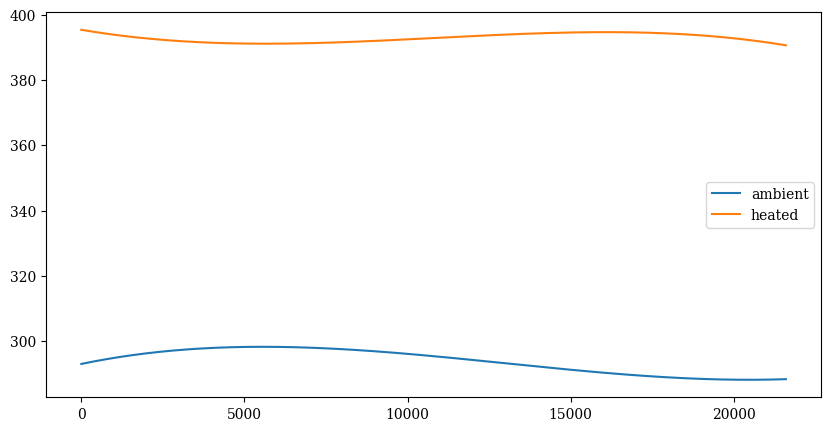

heated_temps:  [395.45674106 395.44649263 395.4362589  ... 390.71759743 390.70770694
 390.69780194]
ambient_temps:  [292.97939172 292.99186969 293.00433051 ... 288.30140578 288.30339417
 288.30539389]


In [22]:
# generate physical temperatures and drifts
#--------
# add here
ambient_rms = 3
heated_rms = 1
drift_order = 4

ambient_coeffs = ambient_rms * np.random.randn(drift_order)
ambient_coeffs[0] = 293
heated_coeffs = heated_rms * np.random.randn(drift_order)
heated_coeffs[0] = 293+100
n_times = 3600
xx = np.linspace(-1, 1, n_times)
times = np.linspace(0, 6*3600, n_times)
ambient_temps = np.polynomial.chebyshev.Chebyshev(ambient_coeffs)(xx)
heated_temps = np.polynomial.chebyshev.Chebyshev(heated_coeffs)(xx)
plt.plot(times, ambient_temps, label='ambient')
plt.plot(times, heated_temps, label='heated')
plt.legend()
plt.show()

print("heated_temps: ", heated_temps)
print("ambient_temps: ", ambient_temps)

internal_load
heated_load
Done


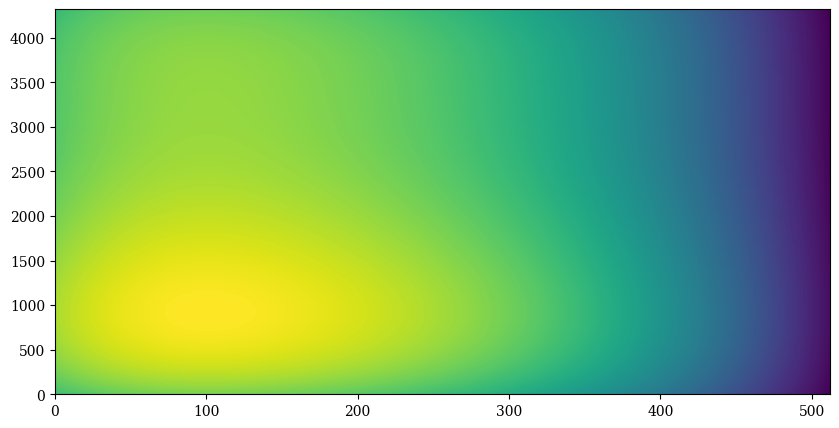

In [ ]:
test_receiver = Receiver(
    gamma_rec_s2p_path='../lab_measurements/RecBlockSDR0.s2p',
    gains_s2p_path='../lab_measurements/RecBlock0.s2p',
    t_unc_scale=300,
    t_sin_scale=25,
    t_cos_scale=-25,
    t_0_scale=400
    )

test_receiver.change_freqs(np.linspace(60*un.MHz, 80*un.MHz, 1024))

open_load = Load(
                 label='open',
                 termination_type='open',
                 freqs=test_receiver.freqs,
                 physical_chebyshev_coeffs=ambient_coeffs)

short_load = Load(
                 label='short',
                 termination_type='short',
                 freqs=test_receiver.freqs,
                 physical_chebyshev_coeffs=ambient_coeffs,)

long_open = Load(
                 label='long_open',
                 termination_type='open',
                 effective_cable_length=10*un.m,
                 freqs=test_receiver.freqs,
                 physical_chebyshev_coeffs=ambient_coeffs,)

long_short = Load(
                 label='long_short',
                 termination_type='short',
                 effective_cable_length=10*un.m,
                 freqs=test_receiver.freqs,
                 physical_chebyshev_coeffs=ambient_coeffs,)


matched_ambient = Load(
                termination_impedence=gamma_db_to_impedence(-30),
                freqs=test_receiver.freqs,
                effective_cable_length=0*un.m,
                label='internal_load',
                 physical_chebyshev_coeffs=ambient_coeffs,)

heated_load = Load(
                termination_impedence=gamma_db_to_impedence(-20),
                freqs=test_receiver.freqs,
                effective_cable_length=0*un.m,
                label='heated_load',
                 physical_chebyshev_coeffs=heated_coeffs,)

test_src = Load(
                termination_impedence=100*un.Ohm,
                freqs=test_receiver.freqs,
                effective_cable_length=5*un.m,
                label='antenna',
                 physical_chebyshev_coeffs=np.array([293]),)


noise_diode = Load(noise_temperature=2000,
                termination_impedence=gamma_db_to_impedence(-30),
                freqs=test_receiver.freqs,
                effective_cable_length=0*un.m,
                fluctuation_scale=5,
                n_time_coeffs=1,
                n_freq_coeffs=4,
                label='noise_diode')

from simulation.toy_sky import ToySky

observation_handler_obj = ObservationHandler(observation_length=6*3600*un.s,
                                                     receiver=test_receiver,
                                                     sources=[
                                                         test_src,
                                                         test_src,
                                                         test_src,
                                                         test_src,
                                                         test_src,
                                                         test_src,
                                                         long_open,
                                                         long_short,
                                                         open_load,
                                                         short_load,
                                                         heated_load,
                                                         ],
                                                    dicke_switch_sources=[
                                                        matched_ambient,
                                                        heated_load,
                                                        # noise_diode
                                                        ],
                                                    dicke_switch_length=150*un.s,
                                                    delta_t=5*un.s,
                                                    n_t_unc_freq_coeffs=3,
                                                    n_t_unc_time_coeffs=3,
                                                    t_unc_amp=10*un.K,
                                                    t_sin_amp=5*un.K,
                                                    t_cos_amp=5*un.K,
                                                    t_0_amp=10*un.K,
                                                    n_t_sin_freq_coeffs=3,
                                                    n_t_sin_time_coeffs=3,
                                                    n_t_cos_freq_coeffs=3,
                                                    n_t_cos_time_coeffs=3,
                                                    n_gain_freq_coeffs=1,
                                                    n_gain_time_coeffs=5,
                                                    n_t_0_freq_coeffs=2,
                                                    n_t_0_time_coeffs=3,
                                                    gain_fluctuation_amp_frac=0.1**2,
                                                    temp_sens_variance=0.02**2)

plt.pcolormesh(observation_handler_obj.gains)

In [24]:
# Time Static Case
simulation_dir = '../simulated_data'

time_static_case_dir = 'case_2'

savepath = f'{simulation_dir}/{time_static_case_dir}'

os.makedirs(savepath,
          exist_ok=True)

observation_handler_obj.save_to_hdf5(filepath=f"{savepath}/sim_data.hdf5")
open_load.export_to_s2p(savepath)
short_load.export_to_s2p(savepath)
long_open.export_to_s2p(savepath)
long_short.export_to_s2p(savepath)
matched_ambient.export_to_s2p(savepath)
heated_load.export_to_s2p(savepath)
test_src.export_to_s2p(savepath)
test_receiver.export_to_s2p(savepath)
noise_diode.export_to_s2p(savepath)